# Adım 3a · Elle MLP (PyTorch tensörleriyle)

*3. adım iki notebook: 3a ağı elle kuruyoruz (bu), 3b aynısını `nn.Module` ve optimizer'la standart haliyle yazıp 2,42'yi geçmeye çalışacağız.*

## MLP nedir

2a'daki LinearRegression tek bir formüldü: `tahmin = x · w + b`. Bunu bir **nöron** gibi düşün: girişleri ağırlıklarla çarpar, toplar.

**MLP (multi-layer perceptron)** bu nöronlardan bir katman kurar ve arkasına bir tane daha ekler:

```
x (8 feature) ──► gizli katman: 32 nöron, her biri kendi w'si ile bir LR ──► ReLU ──► çıkış: 1 nöron ──► tahmin
```

Sihirli kısım **ReLU**: `relu(z) = max(0, z)`, yani negatifi sıfırla. Bu olmasaydı iki doğrusal katman üst üste yine tek bir doğrusal formüle çökerdi (LR'den farkı kalmazdı). ReLU her gizli nörona bir "kırılma noktası" verir; 32 kırık çizgi toplanınca ağ eğri, köşeli, etkileşimli ilişkileri taklit edebilir. Yani yaz×saat'i ona elle vermemize gerek yok, umarız kendisi bulur.

**Nasıl öğreniyor (gradient descent):**
1. **Forward:** mevcut ağırlıklarla tahmin yap.
2. **Loss:** tahmin ne kadar yanlış? (MSE, Cengo seçti)
3. **Backward:** her ağırlık için "bunu biraz artırırsam loss nasıl değişir?" (gradyan). PyTorch bunu `loss.backward()` ile otomatik hesaplar: buna **autograd** denir.
4. **Güncelleme:** her ağırlığı gradyanın tersi yönünde biraz kaydır: `w = w - lr · gradyan`.
5. Tekrarla.

Boosting'de her yeni ağaç hatayı düzeltiyordu; burada aynı ağırlıklar binlerce kez küçük adımlarla düzeltiliyor. 3a'da bu adımların hepsini elle yazıyoruz; 3b'de PyTorch'un hazır parçaları aynı işi yapacak.

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from ruzgar.data import load_aligned, split

aligned = load_aligned()
train, test = split(aligned)
train2, val = split(train, pd.Timestamp("2025-08-01", tz="UTC"))  # 2b'deki gibi: train'in son 3 ayı validation
print(torch.__version__, "| GPU:", torch.cuda.is_available())
len(train2), len(val)

2.15.0+cu132 | GPU: True


(12423, 2206)

## 1. Feature'lar ve standardizasyon

**Feature (Cengo seçti):** 2a'nın feature'ları, etkileşimler hariç: gfs, saat ve ay sin/cos, u/v, hamle → 8 sütun. Sin/cos ve u/v ağ için iyi (23 ile 0 saatin, 359° ile 1°'nin yakın olduğunu bilir). Yaz×saat ve kuzeyli bayrağını vermiyoruz: ağın onları kendisi bulup bulamadığını görmek istiyoruz.

**Standardizasyon:** her sütunu `(x − ortalama) / std` ile ortalaması 0, std'si 1 olacak hale getiriyoruz. Neden: gfs 0–28 arası, sin/cos −1…1 arası. Ölçekler çok farklıysa gradient descent büyük sütunun ağırlığına dev adımlar, küçüğüne minik adımlar atar ve dengesiz öğrenir. LR'de buna gerek yoktu (kapalı formülle tek seferde çözülüyordu), ağaçta da yoktu (ağaç yalnız "büyük mü küçük mü" diye bakar).

**Ortalama ve std'yi yalnız train2'den alıyoruz.** Val ya da test'in istatistiğini kullanmak, geleceğin bilgisini eğitime sızdırmak olur (yine leakage).

In [2]:
def ozellikler(df):
    saat = df["time"].dt.hour
    ay = df["time"].dt.month
    yon = np.deg2rad(df["dir_deg_gfs"])
    X = pd.DataFrame(index=df.index)
    X["gfs"] = df["speed_kn_gfs"]
    X["saat_sin"] = np.sin(2 * np.pi * saat / 24)
    X["saat_cos"] = np.cos(2 * np.pi * saat / 24)
    X["ay_sin"] = np.sin(2 * np.pi * ay / 12)
    X["ay_cos"] = np.cos(2 * np.pi * ay / 12)
    X["u_ruzgar"] = df["speed_kn_gfs"] * np.sin(yon)
    X["v_ruzgar"] = df["speed_kn_gfs"] * np.cos(yon)
    X["hamle_gfs"] = df["gust_kn_gfs"]
    return X

ort = ozellikler(train2).mean()   # yalnız train2'den
std = ozellikler(train2).std()

def tensore(df):
    """DataFrame -> standardize edilmiş feature tensörü ve hedef tensörü."""
    X = (ozellikler(df) - ort) / std
    x = torch.tensor(X.to_numpy(), dtype=torch.float32)
    y = torch.tensor(df["speed_kn_obs"].to_numpy(), dtype=torch.float32).unsqueeze(1)
    return x, y

x_train, y_train = tensore(train2)
x_val, y_val = tensore(val)
print("x_train:", x_train.shape, " y_train:", y_train.shape)
x_train[:3]

x_train: torch.Size([12423, 8])  y_train: torch.Size([12423, 1])


tensor([[-1.0210,  0.3655,  1.3657,  1.2995,  0.2790,  0.5096, -0.6906, -0.9281],
        [-0.9643,  0.7066,  1.2245,  1.2995,  0.2790, -0.4883, -0.3162, -1.0321],
        [-1.0776,  0.9995,  0.9997,  1.2995,  0.2790,  0.0038, -0.1298, -1.0113]])

**Tensör** = PyTorch'un numpy dizisi. Farkı: GPU'ya taşınabilir ve üzerinde yapılan işlemleri kaydedip gradyan hesaplayabilir.

**Şekiller (shape):** `x_train` 12.423 satır × 8 sütun. `y_train` 12.423 × 1. `.unsqueeze(1)` düz bir listeyi (12423,) tek sütunlu bir matrise (12423, 1) çevirir; ağın çıkışı da (satır, 1) olacağı için şekiller uysun diye.

Not: veri küçük (12 bin × 8), bu yüzden CPU'da çalışıyoruz. GPU'ya taşımanın maliyeti hesaptan uzun sürerdi; GPU 3b'de ve özellikle Proje B'de işe yarayacak.

## 2. Ağırlıklar

| parametre | şekil | anlamı |
|---|---|---|
| `W1` | 8 × 32 | her gizli nöronun 8 girişe verdiği ağırlık |
| `b1` | 32 | her gizli nöronun sabiti |
| `W2` | 32 × 1 | çıkış nöronunun 32 gizli nörona verdiği ağırlık |
| `b2` | 1 | çıkışın sabiti |

Toplam 8·32 + 32 + 32 + 1 = **321 parametre**. (LR'de 9'du.)

**Neden rastgele başlıyoruz:** hepsi 0 olsaydı 32 gizli nöron birebir aynı olur, aynı gradyanı alır ve sonsuza kadar aynı kalırdı; 32 nöronun bir anlamı kalmazdı. Rastgelelik simetriyi kırar. `* (2/8) ** 0.5` ölçeği (He başlatması) ReLU'lu ağlarda sinyalin katmanlardan geçerken ne sönmesini ne patlamasını sağlar.

**`requires_grad_()`**: PyTorch'a "bu tensörün gradyanını hesapla" der. Yalnız öğrenilecek parametrelerde açıyoruz; veri (`x_train`) öğrenilmez.

In [3]:
GIZLI = 32
torch.manual_seed(0)  # aynı rastgele başlangıç, aynı sonuç

W1 = (torch.randn(8, GIZLI) * (2 / 8) ** 0.5).requires_grad_()
b1 = torch.zeros(GIZLI, requires_grad=True)
W2 = (torch.randn(GIZLI, 1) * (1 / GIZLI) ** 0.5).requires_grad_()
b2 = torch.zeros(1, requires_grad=True)
parametreler = [W1, b1, W2, b2]

print("parametre sayısı:", sum(p.numel() for p in parametreler))

parametre sayısı: 321


## 3. Forward: tahmin

`@` matris çarpımı. `x @ W1`: (satır × 8) @ (8 × 32) → (satır × 32), yani her satır için 32 gizli nöronun çıktısı. `+ b1` her sütuna kendi sabitini ekler.

Aynı fonksiyonu hem eğitimde hem validation'da kullanacağız.

In [4]:
def ileri(x):
    gizli = torch.relu(x @ W1 + b1)   # (satır, 32): 32 LR, negatifler sıfırlanmış
    return gizli @ W2 + b2             # (satır, 1): gizli nöronların ağırlıklı toplamı

# Henüz eğitilmemiş ağın tahmini: rastgele, saçma olmalı
with torch.no_grad():
    print("ilk 5 tahmin:", ileri(x_train[:5]).squeeze().tolist())
    print("gerçek      :", y_train[:5].squeeze().tolist())

ilk 5 tahmin: [-0.24075990915298462, 0.3151760995388031, 0.1734037697315216, 0.3295134902000427, 0.3377678394317627]
gerçek      : [2.0, 5.0, 2.0, 6.0, 4.0]


`torch.no_grad()`: "bu blokta gradyan kaydı tutma". Yalnız bakmak istediğimizde (değerlendirme, ağırlık güncelleme) kullanılır; hem hızlı hem bellek dostu.

## 4. Eğitim döngüsü

Her tur (**epoch**) bütün train2'yi bir kez görür. Burada her epoch'ta tek bir adım atıyoruz (full-batch gradient descent); 3b'de veriyi küçük parçalara bölüp (mini-batch) epoch başına çok adım atacağız.

**`lr` (learning rate):** her adımın büyüklüğü. Çok küçük → çok yavaş öğrenir. Çok büyük → minimumun üstünden atlar, loss zıplar ya da patlar. 0,05'i Pezo birkaç değer deneyip seçti; 5. bölümde senin deneyeceğin şey bu.

Döngünün içindeki dört satır, bütün derin öğrenmenin kalbi:

In [5]:
LR = 0.05
EPOCH = 3000
gecmis = []  # her 50 epoch'ta train ve val MAE'si

for epoch in range(EPOCH + 1):
    # 1) forward
    tahmin = ileri(x_train)
    # 2) loss: MSE
    loss = ((tahmin - y_train) ** 2).mean()
    # 3) backward: loss'un her parametreye göre gradyanı -> W1.grad, b1.grad, ...
    loss.backward()
    # 4) güncelleme: gradyanın tersine küçük bir adım; sonra gradyanı sıfırla
    with torch.no_grad():
        for p in parametreler:
            p -= LR * p.grad
            p.grad.zero_()   # sıfırlamazsak bir sonraki backward üstüne EKLER

    if epoch % 50 == 0:
        with torch.no_grad():
            mae_train = (tahmin - y_train).abs().mean().item()
            mae_val = (ileri(x_val) - y_val).abs().mean().item()
        gecmis.append({"epoch": epoch, "train": mae_train, "val": mae_val})
        if epoch % 500 == 0:
            print(f"epoch {epoch:5d}   loss {loss.item():7.2f}   train MAE {mae_train:.3f}   val MAE {mae_val:.3f}")

epoch     0   loss  116.54   train MAE 9.001   val MAE 4.873


epoch   500   loss   10.38   train MAE 2.455   val MAE 2.474


epoch  1000   loss   10.17   train MAE 2.428   val MAE 2.449


epoch  1500   loss   10.03   train MAE 2.409   val MAE 2.422


epoch  2000   loss    9.87   train MAE 2.388   val MAE 2.397


epoch  2500   loss    9.79   train MAE 2.379   val MAE 2.389


epoch  3000   loss    9.69   train MAE 2.365   val MAE 2.386


**`p.grad.zero_()` neden şart:** PyTorch gradyanları biriktirir (`+=`). Sıfırlamazsan her adımda önceki bütün adımların gradyanı da eklenir ve adımlar giderek büyür. Klasik başlangıç hatası.

`.item()` tek sayılık bir tensörü düz Python sayısına çevirir.

## 5. Öğrenme eğrisi

son: train 2.365   val 2.386


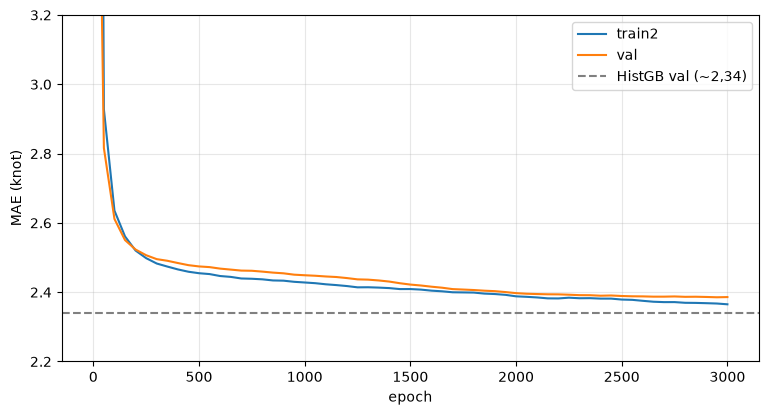

In [6]:
g = pd.DataFrame(gecmis)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(g["epoch"], g["train"], label="train2")
ax.plot(g["epoch"], g["val"], label="val")
ax.axhline(2.34, color="gray", linestyle="--", label="HistGB val (~2,34)")
ax.set_ylim(2.2, 3.2)
ax.set_xlabel("epoch")
ax.set_ylabel("MAE (knot)")
ax.legend()
ax.grid(alpha=0.3)
print(f"son: train {g['train'].iloc[-1]:.3f}   val {g['val'].iloc[-1]:.3f}")

Pezo'nun ölçümü: 3000 epoch sonunda val **~2,39**. HistGB'nin val'i (~2,34) henüz geçilmedi ama 321 parametrelik, elle yazılmış, en basit eğitim yöntemiyle eğitilmiş bir ağ için yakın. Eğri hâlâ yavaşça düşüyor: daha çok epoch, mini-batch ve daha akıllı bir optimizer (Adam) 3b'nin konusu.

Bu ağın ne bildiğine dikkat: ona yaz×saat ya da kuzeyli bayrağı vermedik, ama 2a'nın elle feature'lı LR'sinden (test 2,90) çok daha iyi. Etkileşimleri ReLU'lu gizli nöronlarla kendisi kurmuş.

## 6. Alıştırma: learning rate (sen yapıyorsun)

2. bölümdeki hücreyi (ağırlıkları baştan başlatır) ve 4. bölümdeki döngüyü `LR = 0.01` ve `LR = 0.5` ile ayrı ayrı yeniden çalıştır. Her seferinde son val MAE'yi aşağıya yaz.

İpucu: önce 2. bölümü çalıştırmazsan eğitim kaldığı yerden devam eder, kıyas bozulur.

Sorular: 0,01'de ne oluyor? 0,5'te ne oluyor? Neden?

In [7]:
# LR = 0.01 → son val MAE:
# LR = 0.05 → son val MAE: ~2,39
# LR = 0.5  → son val MAE:
# Ne gözledin:
